# Experiment 7 - Part 1: Asking Questions About Images with Gemini Vision

**Course:** HAAI302COM - Artificial Intelligence Laboratory

Visual Question Answering (VQA) means giving a model an **image and a question** and getting back an **answer**. Modern multimodal LLMs (GPT-4V, Gemini, LLaVA) do this with one chat call. In this notebook we learn the mechanics: how an image travels inside a chat message, what it costs in tokens, and how the prompt and the image resolution change the answer.

We use three kinds of images, taken from public benchmarks: everyday **photos** (VQAv2), **charts** (ChartQA) and scanned **documents** (DocVQA). The next notebook scores a whole set; this one builds understanding on a handful of examples.

## 0. Setup

`vqa_utils.py` (next to this notebook) holds the helper `ask()`. It sends the image and question to Gemini through the **OpenAI SDK** (Gemini exposes an OpenAI-compatible endpoint) and stores every answer in `llm_cache.json`, so re-running costs no API calls. Put `GEMINI_API_KEY=...` in a `.env` file to call the API afresh.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import vqa_utils as vu

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 170)
data = json.load(open("data/vqa_set.json"))
df = pd.DataFrame(data)
print(len(df), "questions")

90 questions


## 1. The data: three kinds of images

`data/vqa_set.json` has 30 questions per image type. Each row holds the image path, the question, and the human reference answers (`answers`; VQAv2 has 10 annotators per question, ChartQA one, DocVQA a few spellings). `answer_type` is the dataset's own label for the kind of question.

In [2]:
print(df.groupby("kind").size())
df[["kind", "question", "gold", "answer_type"]].groupby("kind").head(3)

kind
chart       30
document    30
photo       30
dtype: int64


,kind,question,gold,answer_type
0,photo,Where is he looking?,down,other
1,photo,What is the background metal structure?,platform,other
2,photo,What color is the court?,green,other
30,chart,What's the color of graph with 56 as the highest value?,Blue,0
31,chart,What is the percentage of people who are dissatisfied with Spain's democracy?,68,0
32,chart,"Which country has the highest percentage value of ""a lot""?",Kenya,0
60,document,"What is the ‘actual’ value per 1000, during the year 1975?",0.28,figure/diagram
61,document,What is the name of the fashion wear/clothing advertise,wills lifestyle,Image/Photo
62,document,Why Taco Bell's strong consumer base decreased?,As competitor's joined the price war,free_text


**What to notice:** the three kinds ask for different skills. Photo questions need common sense about scenes (where is he looking), chart questions need reading a value or comparing bars, and document questions need reading printed text, sometimes a long phrase. The 'reference' for a photo is the majority of ten people, so even humans disagree ('down' vs 'at table').

Let us look at one image of each kind with its question. Seeing the data first tells us what the model will be up against.

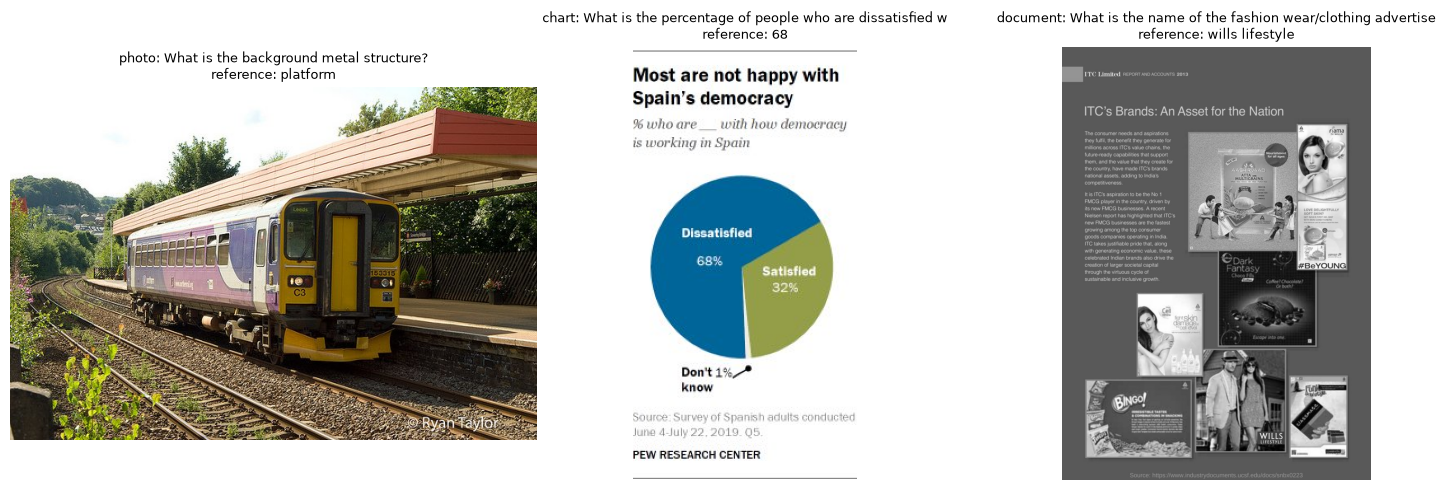

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, kind in zip(axes, ["photo", "chart", "document"]):
    row = df[df.kind == kind].iloc[1]
    ax.imshow(Image.open(row.image)); ax.axis("off")
    ax.set_title(f"{kind}: {row.question[:55]}\nreference: {row.gold}", fontsize=9)
plt.tight_layout(); plt.show()

**What to notice:** the chart is small and the document is full of fine print. A human answers the chart question by looking at one bar; the model must find the label, the bar and its value. The document question needs one number out of a page of text. Both are harder than naming an object.

## 2. How an image travels inside a chat message

A chat API accepts text only, so images are **encoded as text**: the file bytes are turned into a base64 string and wrapped in a *data URI* (`data:image/jpeg;base64,...`). The user message then has a list of *content parts*: one `text` part (the question) and one `image_url` part (the picture).

`image_to_data_uri` does the encoding. Let us build one message and print its structure, with the long base64 string shortened.

In [4]:
row = df[df.kind == "photo"].iloc[0]
uri = vu.image_to_data_uri(row.image)             # file bytes -> base64 text
message = {"role": "user", "content": [
    {"type": "text", "text": row.question},
    {"type": "image_url", "image_url": {"url": uri}},
]}
shown = json.loads(json.dumps(message)); shown["content"][1]["image_url"]["url"] = uri[:60] + "...(%d characters)" % len(uri)
print(json.dumps(shown, indent=1))

{
 "role": "user",
 "content": [
  {
   "type": "text",
   "text": "Where is he looking?"
  },
  {
   "type": "image_url",
   "image_url": {
    "url": "data:image/jpeg;base64,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUDB...(57383 characters)"
   }
  }
 ]
}


**What to notice:** the image is just one more entry in the content list. A 640 by 512 photo became about 57,000 characters of base64 text. Nothing about the call is special: it is the ordinary chat format with a second content part.

## 3. The first call

`ask(path, question, model=...)` builds exactly that message, calls the model and returns the answer plus the token counts. We use `gemini-2.5-flash-lite`, the cheapest vision-capable Gemini model, with `temperature=0` so repeated runs agree.

In [5]:
r = vu.ask(row.image, row.question)
print("question :", row.question)
print("answer   :", r["answer"])
print("reference:", row.answers)
print("tokens   :", r["prompt_tokens"], "prompt,", r["completion_tokens"], "completion")

question : Where is he looking?
answer   : The skateboarder is looking towards the right side of the image.
reference: ['down', 'down', 'at table', 'skateboard', 'down', 'table', 'down', 'down', 'down', 'down']
tokens   : 264 prompt, 13 completion


**What to notice:** the answer is correct and polite but wrong for a benchmark: 'The skateboarder is looking towards the right side of the image.' is a full sentence, and the reference answer is 'down'. Even the content differs, which already shows that a single photo question can have more than one defensible answer. The call used only 264 prompt tokens in total, so the image itself costs roughly 250 tokens.

## 4. What an image costs in tokens

The model never sees pixels directly. The image is cut into patches and each patch becomes tokens, billed like text. Does the token count depend on the content of the picture, or only on its size? We measure `prompt_tokens` for one image of each kind and for the same question with **no image** at all.

In [6]:
rows = []
for kind in ["photo", "chart", "document"]:
    r0 = df[df.kind == kind].iloc[0]
    out = vu.ask(r0.image, r0.question)
    rows.append(dict(kind=kind, image_size=Image.open(r0.image).size, prompt_tokens=out["prompt_tokens"],
                     question_words=len(r0.question.split()), seconds=out["seconds"]))
pd.DataFrame(rows)

,kind,image_size,prompt_tokens,question_words,seconds
0,photo,"(640, 512)",264,4,2.92
1,chart,"(640, 386)",275,11,1.65
2,document,"(1400, 1094)",282,11,1.78


**What to notice:** the prompt token count is almost the same for all three images (264, 275, 282) even though the document image is more than twice as wide as the photo. This Gemini endpoint charges a nearly fixed budget per image, about 250 tokens plus the question, whatever the content. The speed is also similar, 1.7 to 2.9 seconds. Other providers differ: OpenAI bills per 512-pixel tile, so large images cost more there.

## 5. The prompt shapes the answer

VQA benchmarks expect **short** answers ("down", "0.28"), while chat models like to write full sentences. Scoring a sentence against "down" would mark a correct model wrong. Here we ask the same 6 questions in three ways:

- **plain**: just the question.
- **short**: the question plus "Answer with a single word, number or short phrase."
- **system**: the instruction moved into a system message, which applies to every question.

In [7]:
SHORT = " Answer with a single word, number or short phrase."
SYS = "You answer questions about images. Reply with only the answer: one word, one number or a short phrase. No sentences."
sub = pd.concat([df[df.kind == k].iloc[2:4] for k in ["photo", "chart", "document"]])
res = pd.DataFrame({
    "question": sub.question.str[:45].values,
    "reference": sub.gold.values,
    "plain": [vu.ask(p, q)["answer"][:60] for p, q in zip(sub.image, sub.question)],
    "short": [vu.ask(p, q + SHORT)["answer"] for p, q in zip(sub.image, sub.question)],
    "system": [vu.ask(p, q, system=SYS)["answer"] for p, q in zip(sub.image, sub.question)],
})
res

,question,reference,plain,short,system
0,What color is the court?,green,The court in the image is **green**.,Green,Green
1,What about this man's appearance might bother,blue hair,A conservative employer might be bothered by the man's appea,Hair color,Purple hair
2,Which country has the highest percentage valu,Kenya,Kenya,Kenya,Kenya
3,Which state shows the highest fertility rate?,Malawi,Malawi,Malawi,Malawi
4,Why Taco Bell's strong consumer base decrease,As competitor's joined the price war,The provided text states that Taco Bell's strong consumer ba,Price war,Price war
5,What is the no. of Ordinary shares held by Y.,"24,26,435","24,26,435","24,26,435","24,26,435"


**What to notice:** the plain prompt returns sentences ('The court in the image is green.') and sometimes essays, so exact matching would fail even when the model is right. Both the 'short' suffix and the system message fix the format. They are not identical: on the hair question, 'short' gave 'Hair color' (it answered a different question) while 'system' gave 'Purple hair' (the reference says blue hair, so the model also misjudged the colour). The 'why' question about Taco Bell collapsed to 'Price war', which is the right idea but shorter than the reference wording, a problem for exact-match scoring that the next notebook handles with ANLS.

## 6. Experiment: how small can the image get?

Many providers bill more for bigger images, so shrinking is tempting. How far can we shrink before the model stops being able to read, and does it save tokens here? `max_side` shrinks the longer side of the image to that many pixels before sending. We try it on 4 chart questions and 4 document questions, where reading small print matters most, and record whether the answer still matches the reference.

In [8]:
test = pd.concat([df[df.kind == "chart"].iloc[:4], df[df.kind == "document"].iloc[:4]])
rows = []
for side in [64, 128, 256, 512, None]:
    ok, toks = 0, 0
    for _, t in test.iterrows():
        o = vu.ask(t.image, t.question + SHORT, max_side=side)
        ok += vu.normalize(o["answer"]) in [vu.normalize(a) for a in t.answers]
        toks += o["prompt_tokens"]
    rows.append(dict(max_side=side or "original", correct_of_8=ok, avg_prompt_tokens=round(toks / 8)))
pd.DataFrame(rows)

,max_side,correct_of_8,avg_prompt_tokens
0,64,0,284
1,128,1,284
2,256,4,284
3,512,5,284
4,original,5,284


**What to notice:** shrinking is not free. At 64 and 128 pixels the model reads almost nothing (0 and 1 correct of 8), at 256 pixels it gets half, and at 512 pixels it matches the original (5 of 8). The prompt tokens stay at 284 for every size, so on this endpoint shrinking saves nothing in tokens and only hurts. The practical rule: keep text-heavy images at 512 pixels on the long side or more, and do not shrink them just to save cost with Gemini. Note this table uses only 8 questions, so it shows a trend, not a precise accuracy.

## 7. From reading to structured data

A strength of vision LLMs is **extraction**: turn a document image into JSON without any template or OCR rules. We ask for the fields as JSON and parse the reply. The model replies with text, so we always strip the code fence and wrap `json.loads` in a check.

In [9]:
doc = df[df.kind == "document"].iloc[0]
prompt = "List every label and its value that you can read in this document as a JSON object. Reply with JSON only."
raw = vu.ask(doc.image, prompt, max_tokens=700)["answer"]
text = raw.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
try:
    print(json.dumps(json.loads(text), indent=1)[:700])
except json.JSONDecodeError:
    print("not valid JSON, raw reply:", raw[:300])

[
 {
  "label": "FIGURE C.2.",
  "value": "FIGURE C.2."
 },
 {
  "label": "AGE ADJUSTED MOTOR VEHICLE ACCIDENT MORTALITY RATE",
  "value": "AGE ADJUSTED MOTOR VEHICLE ACCIDENT MORTALITY RATE"
 },
 {
  "label": "CANADA",
  "value": "CANADA"
 },
 {
  "label": "0.3",
  "value": "0.3"
 },
 {
  "label": "0.28",
  "value": "0.28"
 },
 {
  "label": "PER",
  "value": "PER"
 },
 {
  "label": "1",
  "value": "1"
 },
 {
  "label": "0",
  "value": "0"
 },
 {
  "label": "0",
  "value": "0"
 },
 {
  "label": "0.26",
  "value": "0.26"
 },
 {
  "label": "0.24",
  "value": "0.24"
 },
 {
  "label": "0.22",
  "value": "0.22"
 },
 {
  "label": "0.2",
  "value": "0.2"
 },
 {
  "label": "1950",
  "value": "1950"



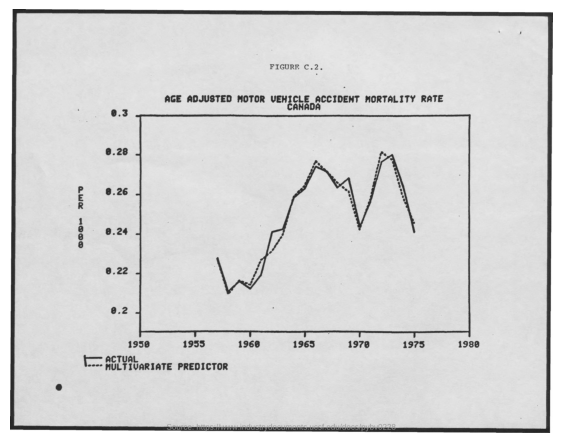

In [10]:
fig = plt.figure(figsize=(7, 8)); plt.imshow(Image.open(doc.image)); plt.axis("off"); plt.show()

**What to notice:** the reply is valid JSON and many values are right (the 0.28 for 1975 that the DocVQA question asks about appears), but the structure is not useful: each entry repeats the same text as both 'label' and 'value', and the model lists axis ticks (0.3, 0.26, 0.24) with no meaning. The image is a chart-like figure, not a form. Extraction works best when we name the fields we want, for example 'return {country, year, rate}', rather than asking for everything.

## 8. When the answer is not in the image

A reliable VQA system must be able to say "I cannot tell". Language models tend to **guess** instead. We ask three questions whose answers cannot be in the picture and see what comes back.

In [11]:
p = df[df.kind == "photo"].iloc[3]
traps = ["What is the name of the person in this picture?",
         "What was the temperature outside when this was taken?",
         "How many days ago was this photo taken?"]
for q in traps:
    print(q, "->", vu.ask(p.image, q + SHORT)["answer"])

What is the name of the person in this picture? -> Unknown


What was the temperature outside when this was taken? -> Indoors


How many days ago was this photo taken? -> 13 years


In [12]:
SAFE = " If the image does not contain the answer, reply exactly: cannot tell."
for q in traps:
    print(q, "->", vu.ask(p.image, q + SHORT + SAFE)["answer"])

What is the name of the person in this picture? -> cannot tell


What was the temperature outside when this was taken? -> cannot tell


How many days ago was this photo taken? -> cannot tell


**What to notice:** without a way out, the model guesses. It said 'Unknown' for the name, 'Indoors' for the temperature (an inference, not an answer) and '13 years' for how many days ago, which is simply invented. With one extra sentence ('If the image does not contain the answer, reply exactly: cannot tell.') all three become 'cannot tell'. The same lesson as in RAG (Experiment 4): permission to say 'I do not know' has to be in the prompt.

## 9. Recap and exercises

- An image is sent as a base64 data URI inside a `content` list, next to the question text.
- On this Gemini endpoint an image costs a nearly fixed ~250 tokens, so shrinking saves nothing and hurts text-heavy images first (other providers bill by size).
- A short-answer instruction is needed for benchmark-style scoring.
- Models guess on unanswerable questions unless the prompt gives an explicit way out.

**Try yourself:** (1) replace the model with `gemini-2.5-flash` and rerun section 6; (2) ask the chart questions in a different language; (3) crop a photo to half its width and see which questions break.

Next: **Notebook 02** scores 90 questions with proper VQA metrics.